### AEMO Data Quality Assessment

The AEMO SA1 and NSW1 datasets covering 2018–2023 were checked before modelling to identify potential time-series data quality issues.

- **Missing values:** No missing values were identified in `REGION`, `SETTLEMENTDATE`, `TOTALDEMAND`, `RRP`, or `PERIODTYPE` for either region.
- **Duplicate timestamps:** No duplicated `SETTLEMENTDATE` values were identified in SA1 or NSW1.
- **Unexpected time gaps:** No unexpected gaps were identified when the expected sampling frequency for each period was considered.
- **Sampling frequency:** Both regions use 30-minute intervals until 1 October 2021 and 5-minute intervals from 1 October 2021 onward.
- **Frequency transition:** The first 5-minute interval occurs at `2021-10-01 00:05:00` in both SA1 and NSW1.
- **Handling:** No observations have been removed or imputed because no missing values, duplicates, or unexpected gaps were identified. The change from 30-minute to 5-minute resolution will be handled during preprocessing to produce a consistent time resolution before forecasting and drift analysis.

In [2]:
# Import libraries for data preparation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Define the project data folders

from pathlib import Path

base_path = Path("/content/drive/MyDrive/ConceptDriftProject/data/raw")

sa1_path = base_path / "SA1"
nsw1_path = base_path / "NSW1"

# Create the folders if they do not already exist
sa1_path.mkdir(parents=True, exist_ok=True)
nsw1_path.mkdir(parents=True, exist_ok=True)

print("SA1 folder:", sa1_path)
print("NSW1 folder:", nsw1_path)

SA1 folder: /content/drive/MyDrive/ConceptDriftProject/data/raw/SA1
NSW1 folder: /content/drive/MyDrive/ConceptDriftProject/data/raw/NSW1


In [6]:
# Check the downloaded AEMO CSV files

sa1_files = sorted(sa1_path.glob("*.csv"))
nsw1_files = sorted(nsw1_path.glob("*.csv"))

print(f"SA1 CSV files found: {len(sa1_files)}")
print(f"NSW1 CSV files found: {len(nsw1_files)}")

print("\nFirst 5 SA1 files:")
for file in sa1_files[:5]:
    print(file.name)

print("\nFirst 5 NSW1 files:")
for file in nsw1_files[:5]:
    print(file.name)

SA1 CSV files found: 72
NSW1 CSV files found: 72

First 5 SA1 files:
PRICE_AND_DEMAND_201801_SA1.csv
PRICE_AND_DEMAND_201802_SA1.csv
PRICE_AND_DEMAND_201803_SA1.csv
PRICE_AND_DEMAND_201804_SA1.csv
PRICE_AND_DEMAND_201805_SA1.csv

First 5 NSW1 files:
PRICE_AND_DEMAND_201801_NSW1.csv
PRICE_AND_DEMAND_201802_NSW1.csv
PRICE_AND_DEMAND_201803_NSW1.csv
PRICE_AND_DEMAND_201804_NSW1.csv
PRICE_AND_DEMAND_201805_NSW1.csv


In [7]:
# Load one sample SA1 file

sample_sa1 = pd.read_csv(sa1_files[0])

print("Shape:", sample_sa1.shape)
print("\nColumns:")
print(sample_sa1.columns.tolist())

sample_sa1.head()

Shape: (1488, 5)

Columns:
['REGION', 'SETTLEMENTDATE', 'TOTALDEMAND', 'RRP', 'PERIODTYPE']


,REGION,SETTLEMENTDATE,TOTALDEMAND,RRP,PERIODTYPE
0,SA1,2018/01/01 00:30:00,1289.10,107.17,TRADE
1,SA1,2018/01/01 01:00:00,1242.28,103.31,TRADE
2,SA1,2018/01/01 01:30:00,1156.19,88.20,TRADE
3,SA1,2018/01/01 02:00:00,1112.46,85.24,TRADE
4,SA1,2018/01/01 02:30:00,1094.20,81.75,TRADE


In [8]:
# Combine all SA1 monthly CSV files into one DataFrame

sa1_data = pd.concat(
    [pd.read_csv(file) for file in sa1_files],
    ignore_index=True
)

print("SA1 combined shape:", sa1_data.shape)
print("Number of files combined:", len(sa1_files))

sa1_data.head()

SA1 combined shape: (302448, 5)
Number of files combined: 72


,REGION,SETTLEMENTDATE,TOTALDEMAND,RRP,PERIODTYPE
0,SA1,2018/01/01 00:30:00,1289.10,107.17,TRADE
1,SA1,2018/01/01 01:00:00,1242.28,103.31,TRADE
2,SA1,2018/01/01 01:30:00,1156.19,88.20,TRADE
3,SA1,2018/01/01 02:00:00,1112.46,85.24,TRADE
4,SA1,2018/01/01 02:30:00,1094.20,81.75,TRADE


In [9]:
# Combine all NSW1 monthly CSV files into one DataFrame

nsw1_data = pd.concat(
    [pd.read_csv(file) for file in nsw1_files],
    ignore_index=True
)

print("NSW1 combined shape:", nsw1_data.shape)
print("Number of files combined:", len(nsw1_files))

nsw1_data.head()

NSW1 combined shape: (302448, 5)
Number of files combined: 72


,REGION,SETTLEMENTDATE,TOTALDEMAND,RRP,PERIODTYPE
0,NSW1,2018/01/01 00:30:00,6912.25,91.86,TRADE
1,NSW1,2018/01/01 01:00:00,6745.63,88.83,TRADE
2,NSW1,2018/01/01 01:30:00,6466.06,73.62,TRADE
3,NSW1,2018/01/01 02:00:00,6279.80,71.49,TRADE
4,NSW1,2018/01/01 02:30:00,6177.31,69.27,TRADE


In [10]:
# Convert SETTLEMENTDATE to datetime

sa1_data["SETTLEMENTDATE"] = pd.to_datetime(
    sa1_data["SETTLEMENTDATE"]
)

nsw1_data["SETTLEMENTDATE"] = pd.to_datetime(
    nsw1_data["SETTLEMENTDATE"]
)


# Sort both datasets chronologically

sa1_data = (
    sa1_data
    .sort_values("SETTLEMENTDATE")
    .reset_index(drop=True)
)

nsw1_data = (
    nsw1_data
    .sort_values("SETTLEMENTDATE")
    .reset_index(drop=True)
)


# Check the date range

print("SA1:")
print("Start:", sa1_data["SETTLEMENTDATE"].min())
print("End:  ", sa1_data["SETTLEMENTDATE"].max())

print("\nNSW1:")
print("Start:", nsw1_data["SETTLEMENTDATE"].min())
print("End:  ", nsw1_data["SETTLEMENTDATE"].max())

SA1:
Start: 2018-01-01 00:30:00
End:   2024-01-01 00:00:00

NSW1:
Start: 2018-01-01 00:30:00
End:   2024-01-01 00:00:00


In [11]:
# Check the time difference between consecutive observations

sa1_time_diff = sa1_data["SETTLEMENTDATE"].diff()

print("Most common SA1 time intervals:")
print(sa1_time_diff.value_counts().head(10))

Most common SA1 time intervals:
SETTLEMENTDATE
0 days 00:05:00    236736
0 days 00:30:00     65711
Name: count, dtype: int64


In [12]:
# Find the first observation where the interval becomes 5 minutes

time_diff = sa1_data["SETTLEMENTDATE"].diff()

five_min_mask = time_diff == pd.Timedelta(minutes=5)

first_five_min_index = five_min_mask.idxmax()

print("First 5-minute interval:")
print(sa1_data.loc[first_five_min_index, "SETTLEMENTDATE"])

print("\nPrevious observation:")
print(sa1_data.loc[first_five_min_index - 1, "SETTLEMENTDATE"])

print("\nTime difference:")
print(time_diff.loc[first_five_min_index])

First 5-minute interval:
2021-10-01 00:05:00

Previous observation:
2021-10-01 00:00:00

Time difference:
0 days 00:05:00


In [13]:
# Check time intervals in NSW1

nsw1_time_diff = nsw1_data["SETTLEMENTDATE"].diff()

print("Most common NSW1 time intervals:")
print(nsw1_time_diff.value_counts().head(10))


# Find first 5-minute interval

five_min_mask_nsw1 = nsw1_time_diff == pd.Timedelta(minutes=5)

first_five_min_index_nsw1 = five_min_mask_nsw1.idxmax()

print("\nFirst 5-minute interval:")
print(nsw1_data.loc[first_five_min_index_nsw1, "SETTLEMENTDATE"])

print("\nPrevious observation:")
print(nsw1_data.loc[first_five_min_index_nsw1 - 1, "SETTLEMENTDATE"])

print("\nTime difference:")
print(nsw1_time_diff.loc[first_five_min_index_nsw1])

Most common NSW1 time intervals:
SETTLEMENTDATE
0 days 00:05:00    236736
0 days 00:30:00     65711
Name: count, dtype: int64

First 5-minute interval:
2021-10-01 00:05:00

Previous observation:
2021-10-01 00:00:00

Time difference:
0 days 00:05:00


In [14]:
# Check for duplicate timestamps in both regions

sa1_duplicates = sa1_data["SETTLEMENTDATE"].duplicated().sum()
nsw1_duplicates = nsw1_data["SETTLEMENTDATE"].duplicated().sum()

print("Duplicate timestamps:")
print(f"SA1:  {sa1_duplicates}")
print(f"NSW1: {nsw1_duplicates}")

Duplicate timestamps:
SA1:  0
NSW1: 0


In [15]:
# Check for unexpected gaps in SA1 and NSW1

transition_date = pd.Timestamp("2021-10-01 00:00:00")

def check_time_gaps(data, region_name):

    # Period 1: expected every 30 minutes
    before = data[data["SETTLEMENTDATE"] <= transition_date].copy()
    before_diff = before["SETTLEMENTDATE"].diff()

    gaps_30min = before[before_diff > pd.Timedelta(minutes=30)]

    # Period 2: expected every 5 minutes
    after = data[data["SETTLEMENTDATE"] >= transition_date].copy()
    after_diff = after["SETTLEMENTDATE"].diff()

    gaps_5min = after[after_diff > pd.Timedelta(minutes=5)]

    print(f"{region_name}")
    print(f"Unexpected gaps before Oct 2021: {len(gaps_30min)}")
    print(f"Unexpected gaps from Oct 2021:   {len(gaps_5min)}")
    print()


check_time_gaps(sa1_data, "SA1")
check_time_gaps(nsw1_data, "NSW1")

SA1
Unexpected gaps before Oct 2021: 0
Unexpected gaps from Oct 2021:   0

NSW1
Unexpected gaps before Oct 2021: 0
Unexpected gaps from Oct 2021:   0



In [16]:
# Check missing values in both datasets

print("SA1 missing values:")
print(sa1_data.isnull().sum())

print("\nNSW1 missing values:")
print(nsw1_data.isnull().sum())

SA1 missing values:
REGION            0
SETTLEMENTDATE    0
TOTALDEMAND       0
RRP               0
PERIODTYPE        0
dtype: int64

NSW1 missing values:
REGION            0
SETTLEMENTDATE    0
TOTALDEMAND       0
RRP               0
PERIODTYPE        0
dtype: int64


In [17]:
# Inspect observations around the change from 30-minute to 5-minute data

sa1_transition = sa1_data[
    (sa1_data["SETTLEMENTDATE"] >= "2021-09-30 22:00:00") &
    (sa1_data["SETTLEMENTDATE"] <= "2021-10-01 01:00:00")
]

sa1_transition[
    ["SETTLEMENTDATE", "TOTALDEMAND", "RRP"]
]

,SETTLEMENTDATE,TOTALDEMAND,RRP
65707,2021-09-30 22:00:00,1432.49,38.57
65708,2021-09-30 22:30:00,1343.26,29.57
65709,2021-09-30 23:00:00,1262.69,13.97
65710,2021-09-30 23:30:00,1230.80,26.20
65711,2021-10-01 00:00:00,1360.13,23.52
65712,2021-10-01 00:05:00,1376.74,17.22
65713,2021-10-01 00:10:00,1338.87,16.97
65714,2021-10-01 00:15:00,1323.73,8.57
65715,2021-10-01 00:20:00,1336.61,8.40
65716,2021-10-01 00:25:00,1326.17,8.49


In [18]:
# Check the size of the combined datasets

print("SA1:")
print(f"Rows: {len(sa1_data):,}")
print(f"Memory: {sa1_data.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

print("\nNSW1:")
print(f"Rows: {len(nsw1_data):,}")
print(f"Memory: {nsw1_data.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

print("\nBoth datasets combined:")
print(f"Total rows: {len(sa1_data) + len(nsw1_data):,}")
print(
    f"Total memory: "
    f"{(sa1_data.memory_usage(deep=True).sum() + nsw1_data.memory_usage(deep=True).sum()) / (1024**2):.2f} MB"
)

SA1:
Rows: 302,448
Memory: 37.50 MB

NSW1:
Rows: 302,448
Memory: 37.79 MB

Both datasets combined:
Total rows: 604,896
Total memory: 75.28 MB


The complete raw AEMO dataset for SA1 and NSW1 (2018–2023) contains 604,896 observations and requires approximately 75.28 MB in memory, making the proposed dataset manageable within the team's available Colab environment.

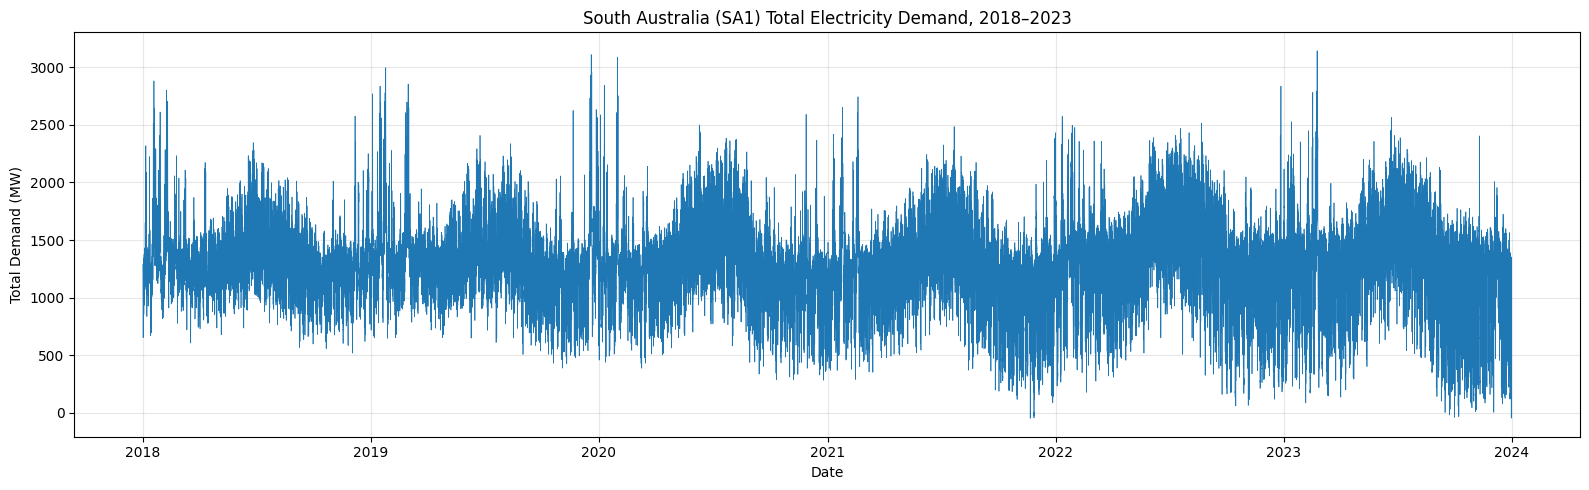

In [19]:
# Plot the full SA1 electricity demand series (2018–2023)

plt.figure(figsize=(16, 5))

plt.plot(
    sa1_data["SETTLEMENTDATE"],
    sa1_data["TOTALDEMAND"],
    linewidth=0.5
)

plt.title("South Australia (SA1) Total Electricity Demand, 2018–2023")
plt.xlabel("Date")
plt.ylabel("Total Demand (MW)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

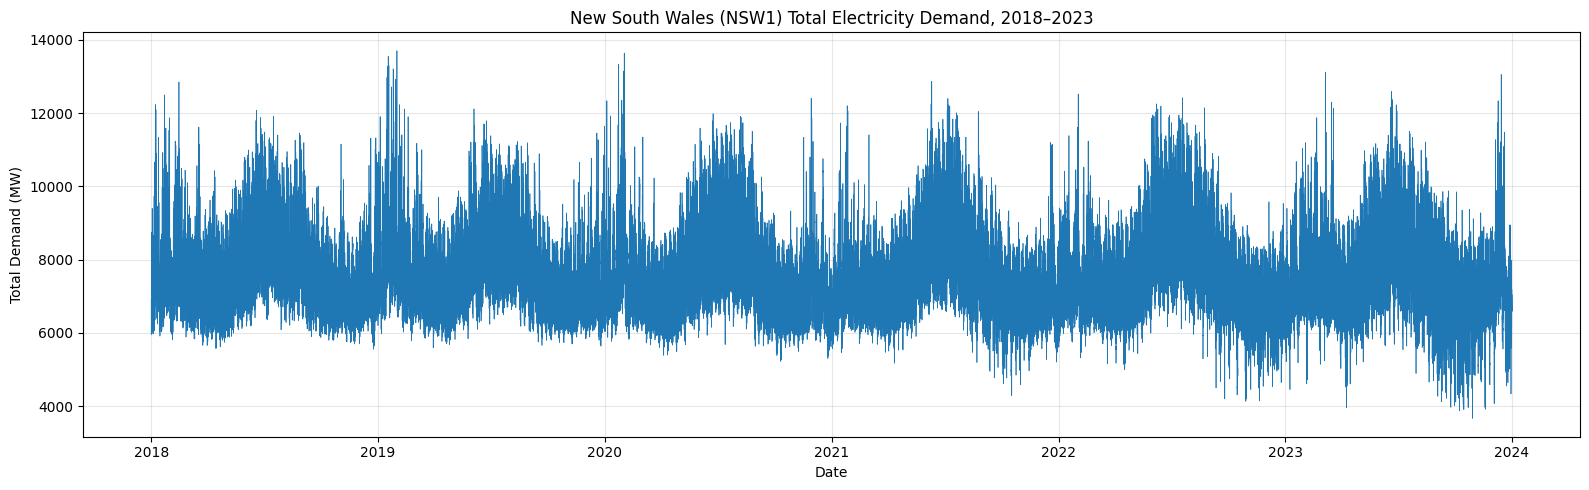

In [20]:
# Plot the full NSW1 electricity demand series (2018–2023)

plt.figure(figsize=(16, 5))

plt.plot(
    nsw1_data["SETTLEMENTDATE"],
    nsw1_data["TOTALDEMAND"],
    linewidth=0.5
)

plt.title("New South Wales (NSW1) Total Electricity Demand, 2018–2023")
plt.xlabel("Date")
plt.ylabel("Total Demand (MW)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# Select the same week from 2019 and 2021 for SA1

week_2019 = sa1_data[
    (sa1_data["SETTLEMENTDATE"] >= "2019-03-15") &
    (sa1_data["SETTLEMENTDATE"] < "2019-03-22")
].copy()

week_2021 = sa1_data[
    (sa1_data["SETTLEMENTDATE"] >= "2021-03-15") &
    (sa1_data["SETTLEMENTDATE"] < "2021-03-22")
].copy()

print("2019 observations:", len(week_2019))
print("2021 observations:", len(week_2021))

print("\n2019:")
print(week_2019["SETTLEMENTDATE"].min(), "to",
      week_2019["SETTLEMENTDATE"].max())

print("\n2021:")
print(week_2021["SETTLEMENTDATE"].min(), "to",
      week_2021["SETTLEMENTDATE"].max())

2019 observations: 336
2021 observations: 336

2019:
2019-03-15 00:00:00 to 2019-03-21 23:30:00

2021:
2021-03-15 00:00:00 to 2021-03-21 23:30:00


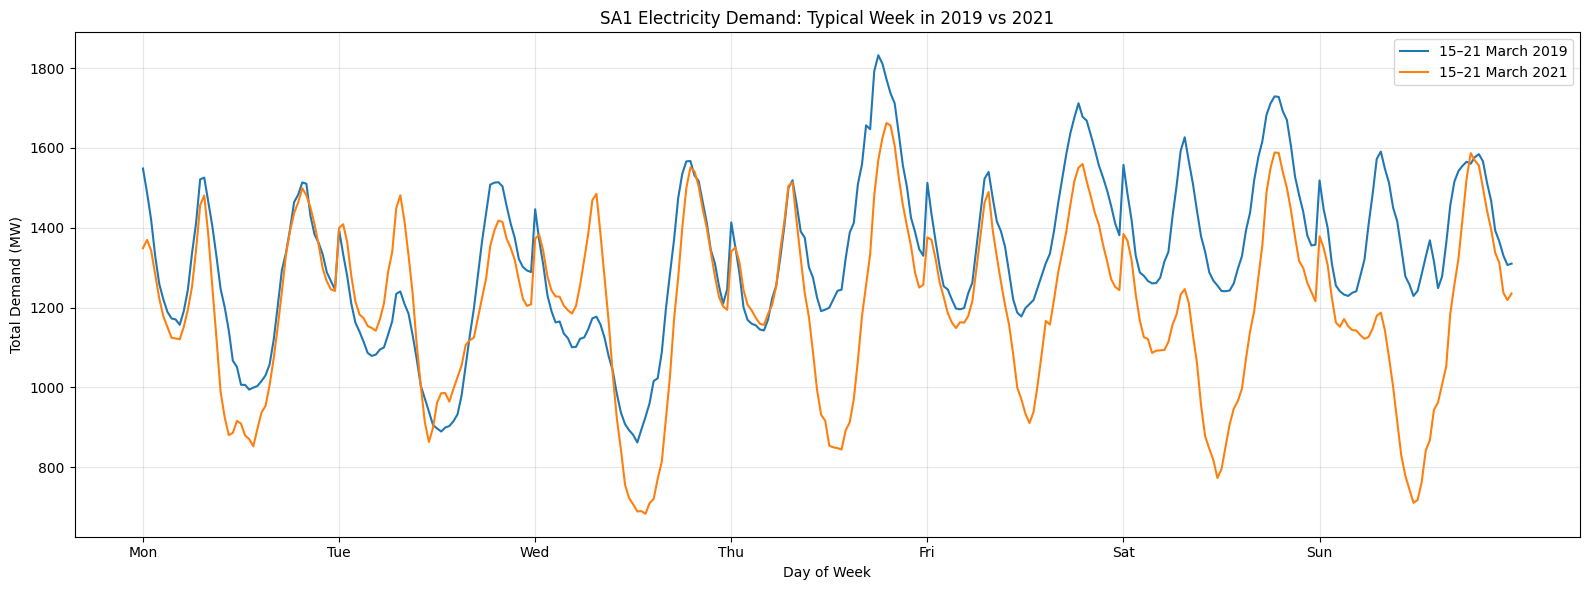

In [22]:
# Compare a typical week in 2019 with the same week in 2021 for SA1

plt.figure(figsize=(16, 6))

# Create positions from 0 to 335 so both weeks align
x = range(len(week_2019))

plt.plot(
    x,
    week_2019["TOTALDEMAND"].values,
    label="15–21 March 2019",
    linewidth=1.5
)

plt.plot(
    x,
    week_2021["TOTALDEMAND"].values,
    label="15–21 March 2021",
    linewidth=1.5
)

# 48 half-hour observations per day
day_positions = [i * 48 for i in range(7)]
day_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.xticks(day_positions, day_labels)

plt.title("SA1 Electricity Demand: Typical Week in 2019 vs 2021")
plt.xlabel("Day of Week")
plt.ylabel("Total Demand (MW)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The selected week in 2021 shows a visibly different demand profile compared with the corresponding week in 2019, with generally lower demand levels and deeper troughs on several days. This provides preliminary evidence that electricity-demand behaviour varies over time. However, this visual comparison alone is not sufficient to establish concept drift; further statistical analysis and drift-detection methods are required to determine whether the observed differences represent a persistent change in the underlying data-generating process.

In [23]:
# Create the fixed three-way split for SA1

train_sa1 = sa1_data[
    (sa1_data["SETTLEMENTDATE"] >= "2018-01-01") &
    (sa1_data["SETTLEMENTDATE"] < "2020-01-01")
].copy()

calibration_sa1 = sa1_data[
    (sa1_data["SETTLEMENTDATE"] >= "2020-01-01") &
    (sa1_data["SETTLEMENTDATE"] < "2020-03-01")
].copy()

test_sa1 = sa1_data[
    sa1_data["SETTLEMENTDATE"] >= "2020-03-01"
].copy()


print("SA1 Split")

print("\nTrain:")
print(train_sa1["SETTLEMENTDATE"].min(), "to",
      train_sa1["SETTLEMENTDATE"].max())
print("Rows:", len(train_sa1))

print("\nCalibration:")
print(calibration_sa1["SETTLEMENTDATE"].min(), "to",
      calibration_sa1["SETTLEMENTDATE"].max())
print("Rows:", len(calibration_sa1))

print("\nTest stream:")
print(test_sa1["SETTLEMENTDATE"].min(), "to",
      test_sa1["SETTLEMENTDATE"].max())
print("Rows:", len(test_sa1))

SA1 Split

Train:
2018-01-01 00:30:00 to 2019-12-31 23:30:00
Rows: 35039

Calibration:
2020-01-01 00:00:00 to 2020-02-29 23:30:00
Rows: 2880

Test stream:
2020-03-01 00:00:00 to 2024-01-01 00:00:00
Rows: 264529


In [24]:
# Create the fixed three-way split for NSW1

train_nsw1 = nsw1_data[
    (nsw1_data["SETTLEMENTDATE"] >= "2018-01-01") &
    (nsw1_data["SETTLEMENTDATE"] < "2020-01-01")
].copy()

calibration_nsw1 = nsw1_data[
    (nsw1_data["SETTLEMENTDATE"] >= "2020-01-01") &
    (nsw1_data["SETTLEMENTDATE"] < "2020-03-01")
].copy()

test_nsw1 = nsw1_data[
    nsw1_data["SETTLEMENTDATE"] >= "2020-03-01"
].copy()


print("NSW1 Split")

print("\nTrain:")
print(train_nsw1["SETTLEMENTDATE"].min(), "to",
      train_nsw1["SETTLEMENTDATE"].max())
print("Rows:", len(train_nsw1))

print("\nCalibration:")
print(calibration_nsw1["SETTLEMENTDATE"].min(), "to",
      calibration_nsw1["SETTLEMENTDATE"].max())
print("Rows:", len(calibration_nsw1))

print("\nTest stream:")
print(test_nsw1["SETTLEMENTDATE"].min(), "to",
      test_nsw1["SETTLEMENTDATE"].max())
print("Rows:", len(test_nsw1))

NSW1 Split

Train:
2018-01-01 00:30:00 to 2019-12-31 23:30:00
Rows: 35039

Calibration:
2020-01-01 00:00:00 to 2020-02-29 23:30:00
Rows: 2880

Test stream:
2020-03-01 00:00:00 to 2024-01-01 00:00:00
Rows: 264529


In [25]:
def load_aemo_region(region, base_path=base_path):
    """
    Load and prepare all AEMO monthly CSV files for a region.

    Parameters
    ----------
    region : str
        AEMO region code, e.g. "SA1" or "NSW1".

    base_path : Path
        Path to the folder containing the regional data folders.

    Returns
    -------
    pd.DataFrame
        Combined dataset sorted chronologically.
    """

    # Locate the region folder
    region_path = Path(base_path) / region

    # Find all monthly CSV files
    files = sorted(region_path.glob("*.csv"))

    if len(files) == 0:
        raise FileNotFoundError(
            f"No CSV files found for {region} in {region_path}"
        )

    # Load and concatenate all monthly files
    data = pd.concat(
        [pd.read_csv(file) for file in files],
        ignore_index=True
    )

    # Convert SETTLEMENTDATE to datetime
    data["SETTLEMENTDATE"] = pd.to_datetime(
        data["SETTLEMENTDATE"]
    )

    # Sort chronologically
    data = (
        data
        .sort_values("SETTLEMENTDATE")
        .reset_index(drop=True)
    )

    print(f"{region} loaded successfully")
    print(f"Files loaded: {len(files)}")
    print(f"Rows: {len(data):,}")
    print(
        f"Period: {data['SETTLEMENTDATE'].min()} "
        f"to {data['SETTLEMENTDATE'].max()}"
    )

    return data

In [26]:
# Test the reusable loader with SA1

test_sa1_loader = load_aemo_region("SA1")

SA1 loaded successfully
Files loaded: 72
Rows: 302,448
Period: 2018-01-01 00:30:00 to 2024-01-01 00:00:00


In [27]:
# Check whether the loader output matches the original SA1 dataset

same_data = test_sa1_loader.equals(sa1_data)

print("Loader output matches original SA1 data:", same_data)

Loader output matches original SA1 data: True
